# 1단계 개선 실험 — WINDOW 크기 비교 (16 / 24 / 32)

**왜 이 실험부터 하는가**
기준선(WINDOW 32)의 미탐 67행 중 52행이 "32행보다 짧은 세그먼트"에서 나왔다 (패딩 세그먼트 41 + score를 못 매긴 8행 미만 11). 이 구조적 미탐은 모델을 아무리 고쳐도 줄지 않고, **윈도우를 줄여 짧은 세그먼트를 패딩 없이 처리하는 것**으로만 줄일 수 있다. 대신 윈도우가 짧아지면 모델이 보는 맥락이 줄어 정상/이상 분리도(PR-AUC)가 떨어질 수 있다. 이 트레이드오프를 수치로 확인한다.

| WINDOW | 패치 수 | 학습에 살리는 행 | 패딩 없이 처리되는 세그먼트 |
|---|---|---|---|
| 16 | 4 | 94.7% | 16행 이상 |
| 24 | 6 | 88.6% | 24행 이상 |
| 32 (기준선) | 8 | 80.1% | 32행 이상 |

**판단 기준**: PR-AUC가 크게 떨어지지 않으면서(기준선 0.949 대비 −0.02 이내) 미탐이 가장 적은 WINDOW를 선택한다. 미탐 10행 미만 차이는 우연 범위로 본다.

**이 노트북의 구성**: 전처리(1~2절)와 모델·학습·평가 코드는 `PatchTST_anomaly_detection.ipynb`와 동일하다. 달라지는 것은 마지막 "실험 루프"뿐이며, 입력은 raw+feat(10채널)로 고정한다. 출력은 `patchtst_outputs_stage1/`에 저장해 기준선 결과를 덮어쓰지 않는다.

## 0. CONFIG · seed (기준선과 동일, 출력 폴더만 분리)

In [1]:
import os, random, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score
from sklearn.ensemble import IsolationForest

%matplotlib inline
warnings.filterwarnings("ignore")

CONFIG = {
    # ── 경로 ──
    "NORMAL_PATH": "press_data_normal.csv",
    "OUTLIER_PATH": "outlier_data.csv",
    "OUT_DIR": "patchtst_outputs_stage1",   # 1단계 실험 전용 출력 폴더 (기준선 결과 보존)
    # ── 컬럼 ──
    "TIME_COL": "TimeStamp",
    "LABEL_COL": "Equipment_state",
    "CHANNELS": ["AI0_Vibration", "AI1_Vibration", "AI2_Current"],   # 원본 센서 3개
    # ── 전처리 ──
    "NOMINAL_DT": 0.1,       # 명목 샘플링 주기(초). EDA에서 중앙값 0.1s 확인
    "GAP_FACTOR": 10,        # 중앙값의 10배(=1초) 넘는 간격이면 세그먼트를 끊는다
    "MAX_INTERP": 3,         # 이 샘플 수 이하의 짧은 결측만 선형 보간
    "TRAIN_RATIO": 0.8,      # normal 앞 80%를 train, 뒤 20%를 val (시간순)
    # ── 윈도우 ──
    # EDA: 세그먼트(버스트) 최대 길이가 50행(5초)이므로 윈도우는 50 이하여야 한다
    "WINDOW": 32,            # 윈도우 길이(샘플) = 3.2초
    "STRIDE": 4,             # 슬라이딩 간격
    "MIN_SEG_INFER": 8,      # 추론 시 이보다 짧은 세그먼트는 score를 매기지 않는다(패딩 한계)
    # ── 파생 변수 ──
    "use_features": True,    # True: 원본+파생 / False: 원본만  (6절에서 둘 다 비교한다)
    "ROLL_WIN": 10,          # 이동 통계 윈도우(샘플) = 1초
    # ── PatchTST ──
    "PATCH_LEN": 4,          # 패치 길이. (WINDOW-PATCH_LEN) % PATCH_STRIDE == 0 이어야 한다
    "PATCH_STRIDE": 4,       # = PATCH_LEN → 겹치지 않는 패치 (마스킹 시 정보 누출 방지)
    "D_MODEL": 64,           # 데이터 2만 행 → 소형 모델
    "N_HEADS": 4,
    "N_LAYERS": 2,
    "D_FF": 128,
    "DROPOUT": 0.1,
    "MASK_RATIO": 0.4,       # 학습 시 가리는 패치 비율 (PatchTST self-supervised 방식)
    "N_INFER_MASKS": 8,      # 추론 시 서로 다른 마스크 개수 (평균 내어 score 안정화)
    # ── 학습 ──
    "BATCH_SIZE": 64,
    "EPOCHS": 60,
    "LR": 1e-3,
    "PATIENCE": 8,           # val loss가 이 epoch 동안 안 좋아지면 중단
    "SEED": 42,
}
assert (CONFIG["WINDOW"] - CONFIG["PATCH_LEN"]) % CONFIG["PATCH_STRIDE"] == 0, "패치가 윈도우를 정확히 덮어야 한다"
os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)


def set_seed(seed: int) -> None:
    """random / numpy / torch / cuda seed를 모두 고정한다. cudnn도 결정론 모드로 둔다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # 같은 입력 → 같은 출력 (속도는 약간 손해)
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

# 그림 색: 정상=파랑, 이상=주황 (고정 순서, 색약 대비 검증된 조합). 임계값/경고=빨강
COLOR = {"normal": "#2a78d6", "outlier": "#eb6834", "thr": "#e34948", "gray": "#9a9a9a", "recon": "#2f9e6f"}
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})

torch 2.13.0+cu126 | device: cuda


In [2]:
# 1단계 실험 변수: 비교할 윈도우 크기. 그 외 설정은 기준선 그대로.
WINDOWS = [16, 24, 32]
for W in WINDOWS:
    assert (W - CONFIG["PATCH_LEN"]) % CONFIG["PATCH_STRIDE"] == 0, f"WINDOW {W}는 패치로 정확히 나뉘지 않음"
print("비교할 WINDOW:", WINDOWS, "| 패치 수:", [(W - CONFIG["PATCH_LEN"]) // CONFIG["PATCH_STRIDE"] + 1 for W in WINDOWS])

비교할 WINDOW: [16, 24, 32] | 패치 수: [4, 6, 8]


## 1. 데이터 로드 · 전처리 (기준선과 동일 — WINDOW와 무관한 단계)

In [3]:
def load_raw(path: str, cfg: dict) -> pd.DataFrame:
    """csv를 읽고 인덱스 컬럼 제거, 시간 컬럼을 datetime으로 변환한다."""
    df = pd.read_csv(path)
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]   # 저장 시 섞인 인덱스 컬럼
    df = df.drop(columns=unnamed)
    df[cfg["TIME_COL"]] = pd.to_datetime(df[cfg["TIME_COL"]])
    return df


raw_normal = load_raw(CONFIG["NORMAL_PATH"], CONFIG)
raw_outlier = load_raw(CONFIG["OUTLIER_PATH"], CONFIG)

for name, df in [("normal", raw_normal), ("outlier", raw_outlier)]:
    tc = CONFIG["TIME_COL"]
    print(f"[{name}] shape={df.shape} | 기간 {df[tc].min()} ~ {df[tc].max()} "
          f"| 라벨 분포 {df[CONFIG['LABEL_COL']].value_counts().to_dict()}")

# 파일 자체가 라벨이다: normal 파일 = 전부 0, outlier 파일 = 전부 1 → 행 단위 라벨은 파일 단위 라벨과 같다
print(f"\n불균형 비율: {len(raw_normal)} : {len(raw_outlier)} = {len(raw_normal)/len(raw_outlier):.1f} : 1")

[normal] shape=(20000, 5) | 기간 2022-07-12 00:00:00.019000 ~ 2022-07-12 01:16:55.828000 | 라벨 분포 {0: 20000}
[outlier] shape=(600, 5) | 기간 2022-07-17 10:51:07.943000 ~ 2022-07-17 10:53:53.540000 | 라벨 분포 {1: 600}

불균형 비율: 20000 : 600 = 33.3 : 1


In [4]:
def resolve_duplicate_timestamps(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """동일 타임스탬프 행을 판별(완전 중복 / 값 충돌)하고 제거 또는 평균 병합한다."""
    tc, chs = cfg["TIME_COL"], cfg["CHANNELS"]
    n_ts_dup = int(df[tc].duplicated().sum())                 # 시각이 같은 '추가' 행 수
    n_full_dup = int(df.duplicated(subset=[tc] + chs).sum())  # 시각+값이 모두 같은 추가 행 수
    n_conflict = n_ts_dup - n_full_dup                        # 시각만 같고 값이 다른 행 수
    print(f"  동일 시각 행: {n_ts_dup}건 → 완전 중복 {n_full_dup}건 (제거), 값 충돌 {n_conflict}건 (평균 병합)")

    before = len(df)
    df = df.drop_duplicates(subset=[tc] + chs)                          # 완전 중복 제거
    df = df.groupby(tc, as_index=False)[chs].mean()                     # 남은 동일 시각은 평균 병합
    print(f"  행 수: {before} → {len(df)}")
    return df


print("[normal]");  normal_p = resolve_duplicate_timestamps(raw_normal, CONFIG)
print("[outlier]"); outlier_p = resolve_duplicate_timestamps(raw_outlier, CONFIG)

[normal]
  동일 시각 행: 1건 → 완전 중복 1건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 20000 → 19999
[outlier]
  동일 시각 행: 0건 → 완전 중복 0건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 600 → 600


In [5]:
def sort_by_time(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """시간순 정렬 + reset_index. 정렬 전후로 순서가 바뀐 행 수를 출력한다."""
    tc = cfg["TIME_COL"]
    n_unsorted = int((df[tc].diff().dt.total_seconds() < 0).sum())   # 시간이 거꾸로 가는 지점 수
    df = df.sort_values(tc).reset_index(drop=True)
    print(f"  시간 역행 지점 {n_unsorted}건 → 정렬 완료, 행 {len(df)}")
    return df


print("[normal]");  normal_p = sort_by_time(normal_p, CONFIG)
print("[outlier]"); outlier_p = sort_by_time(outlier_p, CONFIG)

[normal]
  시간 역행 지점 0건 → 정렬 완료, 행 19999
[outlier]
  시간 역행 지점 0건 → 정렬 완료, 행 600


In [6]:
def assign_segments(df: pd.DataFrame, cfg: dict, gap_sec: float, verbose: bool = True) -> pd.DataFrame:
    """앞 행과의 간격이 gap_sec를 넘는 지점마다 seg_id를 1씩 올려 세그먼트를 나눈다."""
    tc = cfg["TIME_COL"]
    dt = df[tc].diff().dt.total_seconds().fillna(0.0)
    df = df.copy()
    df["seg_id"] = (dt > gap_sec).cumsum().astype(int)
    if verbose:
        seg_len = df.groupby("seg_id").size()
        gaps = dt[dt > gap_sec]
        print(f"  갭 기준 {gap_sec:.2f}s | 세그먼트 {len(seg_len)}개 | 길이 min/median/max = "
              f"{seg_len.min()}/{int(seg_len.median())}/{seg_len.max()}행 | "
              f"갭 크기 min/median/max = {gaps.min():.2f}/{gaps.median():.2f}/{gaps.max():.2f}s")
    return df


GAP_SEC = CONFIG["NOMINAL_DT"] * CONFIG["GAP_FACTOR"]
print("[normal]");  normal_p = assign_segments(normal_p, CONFIG, GAP_SEC)
print("[outlier]"); outlier_p = assign_segments(outlier_p, CONFIG, GAP_SEC)

[normal]
  갭 기준 1.00s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  갭 기준 1.00s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s


In [7]:
def resample_segments(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트별로 0.1초 격자에 맞추고, 짧은 결측만 선형 보간한다. 긴 결측은 삭제한다."""
    tc, chs, dt, max_interp = cfg["TIME_COL"], cfg["CHANNELS"], cfg["NOMINAL_DT"], cfg["MAX_INTERP"]
    out, n_interp, n_dropped, n_snap = [], 0, 0, 0
    for sid, seg in df.groupby("seg_id"):
        t0 = seg[tc].iloc[0]
        k = np.round((seg[tc] - t0).dt.total_seconds() / dt).astype(int)   # 격자 위치(정수)
        seg = seg.assign(k=k.values)
        g = seg.groupby("k")[chs].mean()                # 같은 격자로 스냅된 행은 평균
        g[tc] = seg.groupby("k")[tc].first()            # 실제 행은 원래 시각을 유지(제출 시 병합 키)
        n_snap += len(seg) - len(g)
        g = g.reindex(pd.RangeIndex(0, int(g.index.max()) + 1))   # 빠진 격자를 NaN 행으로 채움
        is_real = g[chs[0]].notna()
        # 결측 run 길이를 계산해 짧은 run만 보간 대상으로 표시
        isna = ~is_real
        run_id = (isna != isna.shift()).cumsum()
        run_len = isna.groupby(run_id).transform("size")
        fill_ok = isna & (run_len <= max_interp)
        interp = g[chs].interpolate("linear", limit_area="inside")
        g.loc[fill_ok, chs] = interp.loc[fill_ok, chs]
        n_interp += int(fill_ok.sum())
        still_na = g[chs[0]].isna()
        n_dropped += int(still_na.sum())
        g = g[~still_na].copy()
        # 보간된 행의 시각은 격자 시각으로 채운다
        grid_time = t0 + pd.to_timedelta(np.round(g.index.values * dt, 3), unit="s")
        g[tc] = g[tc].fillna(pd.Series(grid_time, index=g.index))
        g["is_interp"] = ~is_real[g.index]
        out.append(g[[tc] + chs + ["is_interp"]])
    res = pd.concat(out, ignore_index=True)
    print(f"  행 {len(df)} → {len(res)} | 같은 격자로 병합 {n_snap}행 | 보간 {n_interp}행 | 긴 결측으로 삭제 {n_dropped}격자")
    # 보간되지 않은 긴 결측이 남긴 틈에서 세그먼트를 다시 끊는다(2차 분리)
    res = assign_segments(res, cfg, gap_sec=dt * 1.5, verbose=True)
    return res


print("[normal]");  normal_p = resample_segments(normal_p, CONFIG)
print("[outlier]"); outlier_p = resample_segments(outlier_p, CONFIG)

# 파일 = 라벨 (normal 0, outlier 1)
normal_p["y"] = 0
outlier_p["y"] = 1

# 리샘플 결과 확인: 세그먼트 안의 간격은 전부 0.1초여야 한다
for name, df in [("normal", normal_p), ("outlier", outlier_p)]:
    d = df.groupby("seg_id")[CONFIG["TIME_COL"]].diff().dt.total_seconds().dropna()
    print(f"  {name}: 세그먼트 내부 간격 종류 = {sorted(d.round(3).unique())}")

[normal]


  행 19999 → 19999 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  행 600 → 600 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s
  normal: 세그먼트 내부 간격 종류 = [0.1]
  outlier: 세그먼트 내부 간격 종류 = [0.1]


In [8]:
def time_split(df: pd.DataFrame, ratio: float) -> pd.DataFrame:
    """앞 ratio 비율은 train, 나머지는 val. 경계를 다음 세그먼트 시작으로 이동한다."""
    df = df.copy()
    target = int(len(df) * ratio)
    seg_starts = df.index[df["seg_id"] != df["seg_id"].shift()]      # 각 세그먼트의 첫 행 위치
    split_at = int(seg_starts[seg_starts >= target][0])
    df["split"] = np.where(df.index < split_at, "train", "val")
    tc = CONFIG["TIME_COL"]
    for s in ["train", "val"]:
        part = df[df["split"] == s]
        print(f"  {s}: {len(part)}행, {part['seg_id'].nunique()}세그먼트, {part[tc].min().time()} ~ {part[tc].max().time()}")
    return df


normal_p = time_split(normal_p, CONFIG["TRAIN_RATIO"])
outlier_p["split"] = "test"

  train: 16009행, 481세그먼트, 00:00:00.019000 ~ 01:01:01.732000
  val: 3990행, 118세그먼트, 01:01:04.524000 ~ 01:16:55.828000


In [9]:
FEATURE_COLS = []   # 파생 변수 이름 목록 (아래에서 채움)


def add_features(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트 내부에서만 차분 / 이동 std / 전류 이동 RMS를 계산한다."""
    df = df.copy()
    g = df.groupby("seg_id")
    w = cfg["ROLL_WIN"]
    cols = []
    for ch in cfg["CHANNELS"]:
        df[f"{ch}_diff"] = g[ch].diff().fillna(0.0)                                          # 세그먼트 첫 행은 0
        df[f"{ch}_rstd"] = g[ch].transform(lambda s: s.rolling(w, min_periods=2).std()).fillna(0.0)
        cols += [f"{ch}_diff", f"{ch}_rstd"]
    df["AI2_Current_rms"] = g["AI2_Current"].transform(lambda s: np.sqrt((s ** 2).rolling(w, min_periods=1).mean()))
    cols.append("AI2_Current_rms")
    return df, cols


normal_p, FEATURE_COLS = add_features(normal_p, CONFIG)
outlier_p, _ = add_features(outlier_p, CONFIG)
print("파생 변수:", FEATURE_COLS)

# 세그먼트 경계를 무시하고 차분하면 어떤 일이 생기는지 확인
naive_diff = normal_p["AI2_Current"].diff().abs()                     # 경계 무시
seg_diff = normal_p["AI2_Current_diff"].abs()                          # 세그먼트 내부
boundary = normal_p["seg_id"] != normal_p["seg_id"].shift()
print(f"경계 무시 차분의 99.9% 분위: 내부 {seg_diff.quantile(0.999):.1f} vs 경계에서 {naive_diff[boundary].quantile(0.999):.1f}"
      f" → 경계 행 {int(boundary.sum())}개가 가짜 급변으로 잡힌다")

파생 변수: ['AI0_Vibration_diff', 'AI0_Vibration_rstd', 'AI1_Vibration_diff', 'AI1_Vibration_rstd', 'AI2_Current_diff', 'AI2_Current_rstd', 'AI2_Current_rms']
경계 무시 차분의 99.9% 분위: 내부 94.2 vs 경계에서 460.6 → 경계 행 599개가 가짜 급변으로 잡힌다


In [10]:
def fit_stats(df: pd.DataFrame, cols: list) -> tuple:
    """train 행에서만 mean/std를 계산한다. std가 0인 컬럼은 나눗셈 보호."""
    mu = df[cols].mean()
    sd = df[cols].std().clip(lower=1e-6)
    return mu, sd


def apply_norm(df: pd.DataFrame, cols: list, mu, sd) -> np.ndarray:
    """(x - mu) / sd → float32 배열 [N, C]"""
    return ((df[cols] - mu) / sd).to_numpy(dtype=np.float32)


ALL_COLS = CONFIG["CHANNELS"] + FEATURE_COLS
train_rows = normal_p[normal_p["split"] == "train"]
MU, SD = fit_stats(train_rows, ALL_COLS)
print("train 통계 (원본 채널만 표시):")
print(pd.DataFrame({"mean": MU, "std": SD}).loc[CONFIG["CHANNELS"]].round(4))

# 통계 누수 검증: outlier로 정규화한 값과 train으로 정규화한 값의 스케일 차이
mu_leak, sd_leak = fit_stats(outlier_p, CONFIG["CHANNELS"])
print("\n만약 outlier 통계로 정규화했다면 |z| 평균:",
      ((outlier_p[CONFIG["CHANNELS"]] - mu_leak) / sd_leak).abs().mean().round(2).to_dict())
print("train 통계로 정규화한 outlier |z| 평균   :",
      ((outlier_p[CONFIG["CHANNELS"]] - MU[CONFIG["CHANNELS"]]) / SD[CONFIG["CHANNELS"]]).abs().mean().round(2).to_dict())

train 통계 (원본 채널만 표시):
                 mean       std
AI0_Vibration -0.0001    0.0743
AI1_Vibration -0.0000    0.1277
AI2_Current    1.2750  127.7931

만약 outlier 통계로 정규화했다면 |z| 평균: {'AI0_Vibration': 0.62, 'AI1_Vibration': 0.78, 'AI2_Current': 0.77}
train 통계로 정규화한 outlier |z| 평균   : {'AI0_Vibration': 3.75, 'AI1_Vibration': 1.47, 'AI2_Current': 0.99}


## 2. 함수 정의 (기준선과 동일: 윈도우 생성 · PatchTST · 학습 · score · 평가)

In [11]:
def make_windows(df: pd.DataFrame, Z: np.ndarray, cfg: dict, pad_short: bool, verbose: bool = True):
    """세그먼트 안에서 슬라이딩 윈도우를 만든다.
    반환: X [n, W, C] (정규화 값), IDX [n, W] (df 행 위치, 패딩은 -1)"""
    W, S, min_len = cfg["WINDOW"], cfg["STRIDE"], cfg["MIN_SEG_INFER"]
    X, IDX = [], []
    n_drop_seg = n_drop_rows = n_pad_seg = 0
    for sid, pos in df.groupby("seg_id").indices.items():     # pos: 이 세그먼트 행들의 위치 배열
        L = len(pos)
        if L >= W:
            starts = list(range(0, L - W + 1, S))
            if starts[-1] != L - W:
                starts.append(L - W)                            # 끝 맞춤 윈도우
            for s in starts:
                X.append(Z[pos[s:s + W]]); IDX.append(pos[s:s + W])
        elif pad_short and L >= min_len:
            pad = W - L
            X.append(np.concatenate([Z[pos], np.repeat(Z[pos[-1:]], pad, axis=0)]))   # 마지막 값 반복
            IDX.append(np.concatenate([pos, -np.ones(pad, dtype=int)]))
            n_pad_seg += 1
        else:
            n_drop_seg += 1; n_drop_rows += L
    X = np.stack(X).astype(np.float32); IDX = np.stack(IDX)
    if verbose:
        print(f"  윈도우 {len(X)}개 (shape {X.shape}) | 패딩 세그먼트 {n_pad_seg}개 | "
              f"버린 세그먼트 {n_drop_seg}개 ({n_drop_rows}행)")
    return X, IDX


def build_dataset(cols: list):
    """정규화 → 윈도우 생성까지. 학습용(train만, 패딩 없음)과 추론용(전체, 패딩 허용)을 함께 만든다."""
    Z_n = apply_norm(normal_p, cols, MU[cols], SD[cols])
    Z_o = apply_norm(outlier_p, cols, MU[cols], SD[cols])
    print(" [학습용 normal]");  X_all, IDX_all = make_windows(normal_p, Z_n, CONFIG, pad_short=False)
    split_arr = normal_p["split"].to_numpy()
    is_train = np.all(split_arr[IDX_all] == "train", axis=1)      # 윈도우 전체가 train에 속해야 함
    is_val = np.all(split_arr[IDX_all] == "val", axis=1)
    print(f"   → train 윈도우 {is_train.sum()}개, val 윈도우 {is_val.sum()}개, 경계 걸침 {(~is_train & ~is_val).sum()}개")
    print(" [추론용 normal]");  Xn_inf, IDXn_inf = make_windows(normal_p, Z_n, CONFIG, pad_short=True)
    print(" [추론용 outlier]"); Xo_inf, IDXo_inf = make_windows(outlier_p, Z_o, CONFIG, pad_short=True)
    return {"cols": cols, "X_train": X_all[is_train], "X_val": X_all[is_val],
            "Xn_inf": Xn_inf, "IDXn_inf": IDXn_inf, "Xo_inf": Xo_inf, "IDXo_inf": IDXo_inf}

In [12]:
class RevIN(nn.Module):
    """Reversible Instance Normalization.
    윈도우마다 채널별 mean/std로 정규화하고, 출력에서 되돌린다.
    → 정상/이상이 다른 날짜·부하에서 수집되어 생기는 '절대 수준 차이'를 제거하고 파형(형태)만 보게 한다.
    입력 [B, L, C] → 출력 [B, L, C]"""
    def __init__(self, n_ch: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_ch))    # 채널별 학습 가능한 scale
        self.beta = nn.Parameter(torch.zeros(n_ch))    # 채널별 학습 가능한 shift

    def forward(self, x: torch.Tensor, mode: str) -> torch.Tensor:
        if mode == "norm":
            self.mean = x.mean(dim=1, keepdim=True).detach()                        # [B, 1, C]
            self.std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        elif mode == "denorm":
            return (x - self.beta) / (self.gamma + self.eps) * self.std + self.mean
        raise ValueError(mode)


class Patching(nn.Module):
    """[B, L, C] → [B*C, N, P]  (N = 패치 수, P = 패치 길이). 채널을 배치 차원으로 합쳐 채널 독립 처리."""
    def __init__(self, patch_len: int, stride: int):
        super().__init__()
        self.P, self.S = patch_len, stride

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, C = x.shape
        x = x.permute(0, 2, 1)                              # [B, C, L]
        x = x.unfold(dimension=2, size=self.P, step=self.S) # [B, C, N, P]
        return x.reshape(B * C, x.shape[2], self.P)         # [B*C, N, P]


class PatchTSTReconstructor(nn.Module):
    """마스킹 재구성용 PatchTST.
    forward(x [B, L, C], patch_mask [B*C, N] or None) → 재구성 x_hat [B, L, C]"""
    def __init__(self, n_ch: int, cfg: dict):
        super().__init__()
        L, P, S, D = cfg["WINDOW"], cfg["PATCH_LEN"], cfg["PATCH_STRIDE"], cfg["D_MODEL"]
        self.n_ch, self.L, self.P, self.S = n_ch, L, P, S
        self.N = (L - P) // S + 1                            # 패치 수
        self.revin = RevIN(n_ch)
        self.patching = Patching(P, S)
        self.proj = nn.Linear(P, D)                          # 패치 → 임베딩  [B*C, N, P] → [B*C, N, D]
        self.pos = nn.Parameter(torch.randn(1, self.N, D) * 0.02)   # 학습 가능한 위치 임베딩
        self.mask_token = nn.Parameter(torch.zeros(1, 1, D))        # 가려진 패치 자리에 넣는 토큰
        layer = nn.TransformerEncoderLayer(d_model=D, nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"])
        self.head = nn.Sequential(nn.Flatten(start_dim=1), nn.Dropout(cfg["DROPOUT"]),
                                  nn.Linear(self.N * D, L))   # [B*C, N*D] → [B*C, L]

    def forward(self, x: torch.Tensor, patch_mask: torch.Tensor = None) -> torch.Tensor:
        B, L, C = x.shape
        x = self.revin(x, "norm")                             # [B, L, C]
        p = self.patching(x)                                  # [B*C, N, P]
        z = self.proj(p) + self.pos                           # [B*C, N, D]
        if patch_mask is not None:                            # 가려진 패치의 임베딩을 mask_token으로 교체
            m = patch_mask.unsqueeze(-1).bool()               # [B*C, N, 1]
            z = torch.where(m, self.mask_token.expand_as(z), z)
        z = self.encoder(z)                                   # [B*C, N, D]
        out = self.head(z)                                    # [B*C, L]
        out = out.view(B, C, L).permute(0, 2, 1)              # [B, L, C]
        return self.revin(out, "denorm")

    def patch_to_pos_mask(self, patch_mask: torch.Tensor, B: int) -> torch.Tensor:
        """패치 마스크 [B*C, N] → 위치 마스크 [B, L, C] (가려진 패치가 덮는 시점은 1)"""
        BC, N = patch_mask.shape
        pos = torch.zeros(BC, self.L, device=patch_mask.device)
        for n in range(N):
            seg = pos[:, n * self.S: n * self.S + self.P]
            pos[:, n * self.S: n * self.S + self.P] = torch.maximum(seg, patch_mask[:, n:n + 1])
        return pos.view(B, self.n_ch, self.L).permute(0, 2, 1)


def random_patch_mask(BC: int, N: int, ratio: float, gen: torch.Generator, device) -> torch.Tensor:
    """시퀀스마다 round(ratio*N)개의 패치를 무작위로 가린다. 반환 [BC, N] float(1=가림)"""
    k = max(1, int(round(ratio * N)))
    order = torch.rand(BC, N, generator=gen).argsort(dim=1)
    mask = torch.zeros(BC, N)
    mask.scatter_(1, order[:, :k], 1.0)
    return mask.to(device)


# 모델 크기 확인
_tmp = PatchTSTReconstructor(n_ch=len(ALL_COLS), cfg=CONFIG)
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"패치 수 N = {_tmp.N}, 파라미터 수 = {n_params:,}")
with torch.no_grad():   # shape 확인용 더미 forward
    xb = torch.randn(2, CONFIG["WINDOW"], len(ALL_COLS))
    mk = random_patch_mask(2 * len(ALL_COLS), _tmp.N, CONFIG["MASK_RATIO"], torch.Generator().manual_seed(0), "cpu")
    print("입력", tuple(xb.shape), "→ 출력", tuple(_tmp(xb, mk).shape), "| 위치 마스크", tuple(_tmp.patch_to_pos_mask(mk, 2).shape))
del _tmp

패치 수 N = 8, 파라미터 수 = 84,276
입력 (2, 32, 10) → 출력 (2, 32, 10) | 위치 마스크 (2, 32, 10)


In [13]:
def masked_mse(x_hat, x, pos_mask):
    """가려진 위치에서만 MSE. pos_mask [B, L, C] (1=가림)"""
    return (((x_hat - x) ** 2) * pos_mask).sum() / pos_mask.sum().clamp(min=1.0)


def run_epoch(model, X, cfg, optimizer=None, gen=None):
    """한 epoch. optimizer가 None이면 평가 모드(가중치 갱신 없음)."""
    train = optimizer is not None
    model.train(train)
    n_ch, bs = X.shape[2], cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[order[i:i + bs].numpy()]).to(DEVICE)
        mask = random_patch_mask(xb.shape[0] * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0])
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # Transformer 학습 안정화
            optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model(X_train, X_val, cfg, tag: str):
    """학습 + early stopping. 최적 가중치를 OUT_DIR/patchtst_{tag}.pt 에 저장하고 학습 곡선을 반환한다."""
    set_seed(cfg["SEED"])
    model = PatchTSTReconstructor(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt")
    t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch(model, X_train, cfg, opt, gen_train)
        va = run_epoch(model, X_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))  # val 마스크 고정
        sched.step()
        hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, path)
        else:
            bad += 1
        if ep % 5 == 0 or ep == 1:
            print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]:
            print(f"  [{tag}] early stopping at epoch {ep} (best val {best:.4f})")
            break
    model.load_state_dict(best_state)
    print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s, 가중치 저장 → {path}")
    return model, hist

In [14]:
@torch.no_grad()
def reconstruction_errors(model, X: np.ndarray, cfg: dict) -> np.ndarray:
    """윈도우별·시점별·채널별 재구성 오차 [n, L, C]. 여러 마스크에서 '가려졌을 때'의 오차를 평균한다."""
    model.eval()
    n_ch, bs, K = X.shape[2], cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7)      # 추론 마스크도 고정 → 재현 가능
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        B = xb.shape[0]
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask(B * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        err = torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K)   # 한 번도 안 가려진 시점은 전체 평균
        out.append(err.cpu().numpy())
    return np.concatenate(out)


def aggregate_rows(err: np.ndarray, IDX: np.ndarray, n_rows: int) -> np.ndarray:
    """윈도우 오차 [n, L, C] → 행별 오차 [n_rows, C]. 겹치는 윈도우는 평균, 패딩(-1)은 제외, 미커버 행은 NaN."""
    C = err.shape[2]
    sums = np.zeros((n_rows, C)); cnt = np.zeros(n_rows)
    valid = IDX >= 0
    np.add.at(sums, IDX[valid], err[valid])
    np.add.at(cnt, IDX[valid], 1)
    row_err = np.full((n_rows, C), np.nan)
    row_err[cnt > 0] = sums[cnt > 0] / cnt[cnt > 0, None]
    return row_err


def score_patchtst(tag: str) -> dict:
    """normal(train/val)과 outlier 전체 행에 대해 채널별 오차와 score를 계산한다."""
    d, model = DATA[tag], MODELS[tag]
    err_n = aggregate_rows(reconstruction_errors(model, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
    err_o = aggregate_rows(reconstruction_errors(model, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
    s_n, s_o = np.nanmean(err_n, axis=1), np.nanmean(err_o, axis=1)
    val_mask = (normal_p["split"] == "val").to_numpy()
    fill = np.nanmedian(s_n[val_mask])                     # score를 못 매긴 행(너무 짧은 세그먼트)은 val 중앙값 = "정상으로 간주"
    print(f"  [{tag}] score 없는 행: normal {np.isnan(s_n).sum()}, outlier {np.isnan(s_o).sum()} → val 중앙값 {fill:.4f}으로 채움")
    return {"err_n": err_n, "err_o": err_o,
            "scored_n": ~np.isnan(s_n), "scored_o": ~np.isnan(s_o),
            "score_n": np.where(np.isnan(s_n), fill, s_n), "score_o": np.where(np.isnan(s_o), fill, s_o),
            "cols": d["cols"]}

In [15]:
VAL_MASK = (normal_p["split"] == "val").to_numpy()
TRAIN_MASK = ~VAL_MASK


def thresholds_from_val(score_val: np.ndarray) -> dict:
    """라벨 없이 val 정상 score 분포에서 임계값을 정한다."""
    return {"val_p99": float(np.percentile(score_val, 99)),
            "val_mean+3sd": float(score_val.mean() + 3 * score_val.std())}


def best_f1_threshold(y: np.ndarray, s: np.ndarray) -> float:
    """라벨을 써서 F1이 최대가 되는 임계값 (낙관적 상한)."""
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


def evaluate(score_val: np.ndarray, score_out: np.ndarray, name: str) -> pd.DataFrame:
    """val 정상(0) + outlier(1)에 대해 AUROC / PR-AUC와 임계값별 F1을 계산한다."""
    y = np.r_[np.zeros(len(score_val)), np.ones(len(score_out))]
    s = np.r_[score_val, score_out]
    thr = thresholds_from_val(score_val); thr["best_f1"] = best_f1_threshold(y, s)
    rows = []
    for tname, t in thr.items():
        pred = (s >= t).astype(int)
        rows.append({"model": name, "threshold": tname, "thr_value": t,
                     "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                     "F1": f1_score(y, pred), "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                     "FP(val)": int(((pred == 1) & (y == 0)).sum()), "FN(out)": int(((pred == 0) & (y == 1)).sum())})
    return pd.DataFrame(rows), thr

## 3. 실험 루프 — WINDOW별로 윈도우 생성 → 학습 → score → 평가
각 WINDOW마다 같은 절차를 반복하고, 결과를 한 표에 모은다. 미탐은 세그먼트 길이 구간별로 나눠 "구조적 미탐이 실제로 줄었는지"를 본다.
- `score 없음`: 8행 미만 세그먼트 (어떤 WINDOW에서도 판정 불가)
- `패딩`: 8행 이상 WINDOW 미만 (마지막 값 반복으로 채워 판정)
- `정상 윈도우`: WINDOW 이상

In [16]:
def build_dataset_w(cols: list, cfg: dict) -> dict:
    """build_dataset과 같지만 cfg(WINDOW)를 인자로 받는다."""
    Z_n = apply_norm(normal_p, cols, MU[cols], SD[cols])
    Z_o = apply_norm(outlier_p, cols, MU[cols], SD[cols])
    X_all, IDX_all = make_windows(normal_p, Z_n, cfg, pad_short=False, verbose=False)
    split_arr = normal_p["split"].to_numpy()
    is_train = np.all(split_arr[IDX_all] == "train", axis=1)
    is_val = np.all(split_arr[IDX_all] == "val", axis=1)
    Xn_inf, IDXn_inf = make_windows(normal_p, Z_n, cfg, pad_short=True, verbose=False)
    Xo_inf, IDXo_inf = make_windows(outlier_p, Z_o, cfg, pad_short=True, verbose=False)
    # 학습에 실제로 쓰인 행 비율 (train 윈도우가 덮는 고유 행 수 / train 행 수)
    used_rows = np.unique(IDX_all[is_train]).size
    return {"cols": cols, "X_train": X_all[is_train], "X_val": X_all[is_val],
            "Xn_inf": Xn_inf, "IDXn_inf": IDXn_inf, "Xo_inf": Xo_inf, "IDXo_inf": IDXo_inf,
            "train_row_ratio": used_rows / (normal_p["split"] == "train").sum()}


def seg_len_bucket(df: pd.DataFrame, W: int) -> np.ndarray:
    """세그먼트 길이를 WINDOW 기준 3구간으로 나눈다."""
    L = df.groupby("seg_id")["seg_id"].transform("size").to_numpy()
    return np.where(L < CONFIG["MIN_SEG_INFER"], "score 없음(<8)", np.where(L < W, f"패딩(8~{W-1})", f"정상 윈도우(≥{W})"))


STAGE1 = {}
for W in WINDOWS:
    cfg = dict(CONFIG); cfg["WINDOW"] = W
    tag = f"W{W}"
    print(f"\n==================== WINDOW = {W} ====================")
    d = build_dataset_w(ALL_COLS, cfg)
    print(f"  train 윈도우 {len(d['X_train'])}개 | val 윈도우 {len(d['X_val'])}개 | 학습에 쓰인 train 행 비율 {d['train_row_ratio']:.1%}")
    model, hist = train_model(d["X_train"], d["X_val"], cfg, tag)
    # score
    err_n = aggregate_rows(reconstruction_errors(model, d["Xn_inf"], cfg), d["IDXn_inf"], len(normal_p))
    err_o = aggregate_rows(reconstruction_errors(model, d["Xo_inf"], cfg), d["IDXo_inf"], len(outlier_p))
    s_n, s_o = np.nanmean(err_n, axis=1), np.nanmean(err_o, axis=1)
    fill = np.nanmedian(s_n[VAL_MASK])
    unscored_o = int(np.isnan(s_o).sum())
    s_n = np.where(np.isnan(s_n), fill, s_n); s_o = np.where(np.isnan(s_o), fill, s_o)
    # 평가
    ev, thr = evaluate(s_n[VAL_MASK], s_o, f"PatchTST[{tag}]")
    row = ev[ev["threshold"] == "val_p99"].iloc[0]
    # 미탐·오탐을 세그먼트 길이 구간별로
    pred_o = s_o >= thr["val_p99"]; pred_v = s_n[VAL_MASK] >= thr["val_p99"]
    b_o = seg_len_bucket(outlier_p, W); b_v = seg_len_bucket(normal_p, W)[VAL_MASK]
    fn_by = pd.Series(~pred_o).groupby(b_o).sum().to_dict()
    fp_by = pd.Series(pred_v).groupby(b_v).sum().to_dict()
    STAGE1[W] = {"cfg": cfg, "model": model, "hist": hist, "data": d, "score_n": s_n, "score_o": s_o,
                 "err_o": err_o, "thr": thr, "eval": ev,
                 "summary": {"WINDOW": W, "patches": model.N, "train_windows": len(d["X_train"]),
                             "train_row_ratio": d["train_row_ratio"], "epochs": len(hist["val"]), "best_val_loss": min(hist["val"]),
                             "AUROC": row["AUROC"], "PR-AUC": row["PR-AUC"], "F1@p99": row["F1"],
                             "precision": row["precision"], "recall": row["recall"], "thr_p99": thr["val_p99"],
                             "FN": int(row["FN(out)"]), "FP": int(row["FP(val)"]), "unscored_out": unscored_o,
                             "F1@bestF1": float(ev[ev["threshold"] == "best_f1"]["F1"].iloc[0]),
                             "FN_by_bucket": fn_by, "FP_by_bucket": fp_by}}
    print(f"  → PR-AUC {row['PR-AUC']:.4f} | F1@p99 {row['F1']:.4f} | recall {row['recall']:.4f} | FN {int(row['FN(out)'])} | FP {int(row['FP(val)'])}")
    print(f"    FN 구간별: {fn_by}")


==================== WINDOW = 16 ====================
  train 윈도우 2815개 | val 윈도우 702개 | 학습에 쓰인 train 행 비율 94.7%


  [W16] epoch   1 | train 0.4283 | val 0.1478 | best 0.1478


  [W16] epoch   5 | train 0.1780 | val 0.0743 | best 0.0743


  [W16] epoch  10 | train 0.1496 | val 0.0633 | best 0.0633


  [W16] epoch  15 | train 0.1373 | val 0.0598 | best 0.0598


...

  [W32] epoch  45 | train 0.1012 | val 0.0509 | best 0.0508


  [W32] epoch  50 | train 0.1011 | val 0.0506 | best 0.0506


  [W32] epoch  55 | train 0.0987 | val 0.0505 | best 0.0505


  [W32] epoch  60 | train 0.0997 | val 0.0504 | best 0.0504
  [W32] 학습 시간 4.9s, 가중치 저장 → patchtst_outputs_stage1/patchtst_W32.pt


  → PR-AUC 0.9490 | F1@p99 0.9088 | recall 0.8883 | FN 67 | FP 40
    FN 구간별: {'score 없음(<8)': 11, '정상 윈도우(≥32)': 15, '패딩(8~31)': 41}


## 4. 비교표

In [17]:
cmp = pd.DataFrame([v["summary"] for v in STAGE1.values()]).set_index("WINDOW")
main_cols = ["patches", "train_windows", "train_row_ratio", "AUROC", "PR-AUC", "F1@p99", "precision", "recall", "FN", "FP", "unscored_out", "F1@bestF1", "best_val_loss", "epochs"]
display(cmp[main_cols].round(4))

# 미탐을 구간별로 펼친 표 (구조적 미탐이 줄었는지 확인)
fn_tbl = pd.DataFrame({W: v["summary"]["FN_by_bucket"] for W, v in STAGE1.items()}).fillna(0).astype(int)
fn_tbl.loc["합계"] = fn_tbl.sum()
print("미탐(FN) 세그먼트 길이 구간별 — 열 = WINDOW"); display(fn_tbl)
fp_tbl = pd.DataFrame({W: v["summary"]["FP_by_bucket"] for W, v in STAGE1.items()}).fillna(0).astype(int)
fp_tbl.loc["합계"] = fp_tbl.sum()
print("오탐(FP) 세그먼트 길이 구간별 — p99라 합계는 ≈40으로 고정, 분포만 비교"); display(fp_tbl)
cmp[main_cols].to_csv(os.path.join(CONFIG["OUT_DIR"], "stage1_window_comparison.csv"))

,patches,train_windows,train_row_ratio,AUROC,PR-AUC,F1@p99,precision,recall,FN,FP,unscored_out,F1@bestF1,best_val_loss,epochs
WINDOW,,,,,,,,,,,,,,
16,4,2815,0.9473,0.9826,0.9578,0.9041,0.9296,0.8800,72,40,11,0.9105,0.0521,60
24,6,2035,0.8841,0.9793,0.9517,0.9097,0.9303,0.8900,66,40,11,0.9135,0.0470,60
32,8,1373,0.8036,0.9776,0.9490,0.9088,0.9302,0.8883,67,40,11,0.9135,0.0504,60


미탐(FN) 세그먼트 길이 구간별 — 열 = WINDOW


,16,24,32
score 없음(<8),11,11,11
정상 윈도우(≥16),42,0,0
패딩(8~15),19,0,0
정상 윈도우(≥24),0,34,0
패딩(8~23),0,21,0
정상 윈도우(≥32),0,0,15
패딩(8~31),0,0,41
합계,72,66,67


오탐(FP) 세그먼트 길이 구간별 — p99라 합계는 ≈40으로 고정, 분포만 비교


,16,24,32
score 없음(<8),0,0,0
정상 윈도우(≥16),31,0,0
패딩(8~15),9,0,0
정상 윈도우(≥24),0,25,0
패딩(8~23),0,15,0
정상 윈도우(≥32),0,0,18
패딩(8~31),0,0,22
합계,40,40,40


## 5. 시각화 — 분리도(PR-AUC·F1) vs 미탐, 그리고 outlier score 시계열

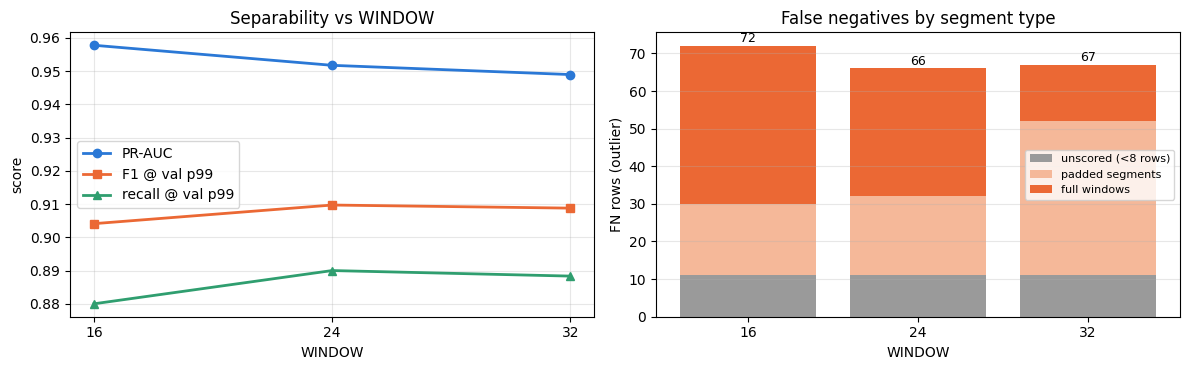

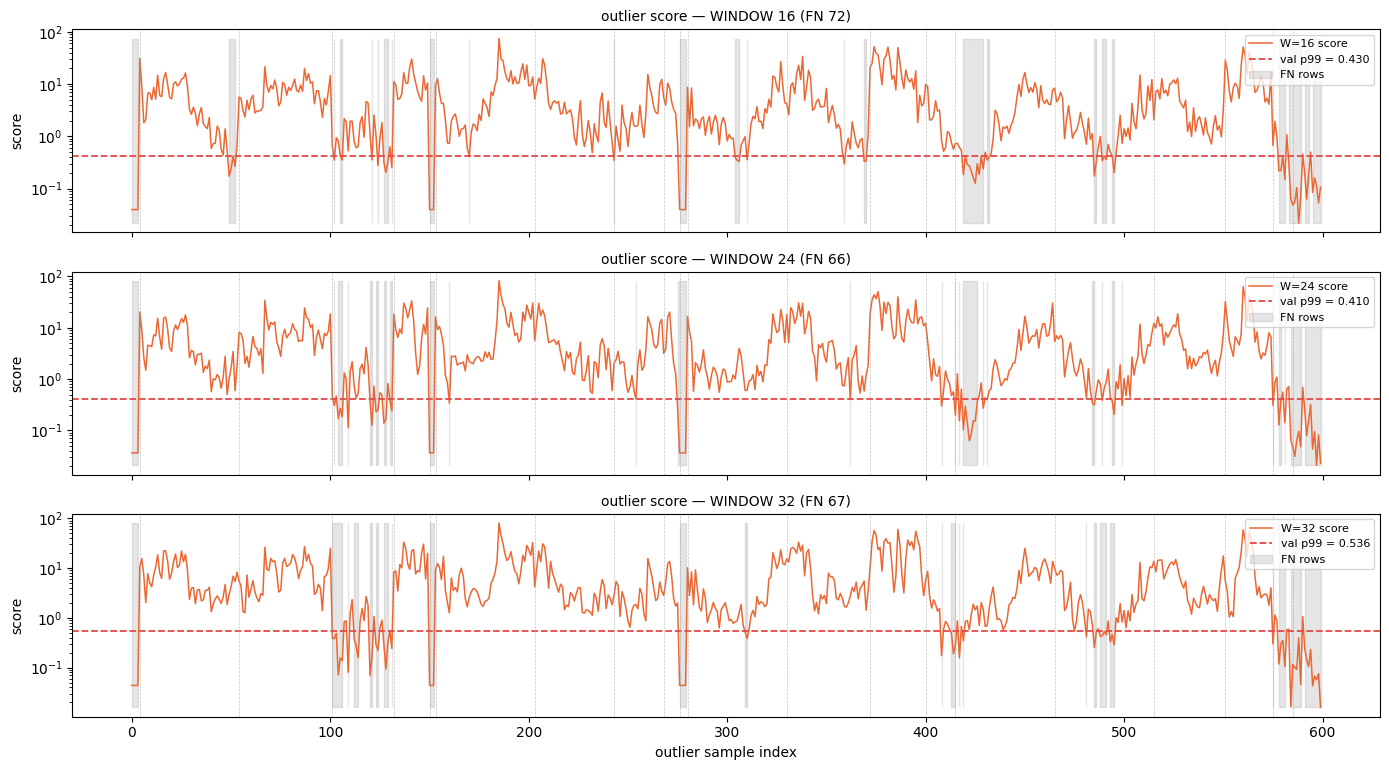

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(cmp.index, cmp["PR-AUC"], marker="o", lw=2, color=COLOR["normal"], label="PR-AUC")
ax.plot(cmp.index, cmp["F1@p99"], marker="s", lw=2, color=COLOR["outlier"], label="F1 @ val p99")
ax.plot(cmp.index, cmp["recall"], marker="^", lw=2, color=COLOR["recon"], label="recall @ val p99")
ax.set_xticks(WINDOWS); ax.set_xlabel("WINDOW"); ax.set_ylabel("score"); ax.set_title("Separability vs WINDOW"); ax.legend(); ax.grid(alpha=0.3)
ax = axes[1]
bottom = np.zeros(len(WINDOWS))
order = ["score 없음(<8)"] + [f"패딩(8~{W-1})" for W in WINDOWS] + [f"정상 윈도우(≥{W})" for W in WINDOWS]
shades = {"none": "#9a9a9a", "pad": "#f5b899", "full": COLOR["outlier"]}
for kind, lab in [("none", "unscored (<8 rows)"), ("pad", "padded segments"), ("full", "full windows")]:
    vals = []
    for W in WINDOWS:
        fb = STAGE1[W]["summary"]["FN_by_bucket"]
        key = "score 없음(<8)" if kind == "none" else (f"패딩(8~{W-1})" if kind == "pad" else f"정상 윈도우(≥{W})")
        vals.append(fb.get(key, 0))
    ax.bar([str(W) for W in WINDOWS], vals, bottom=bottom, color=shades[kind], label=lab); bottom += np.array(vals)
for i, W in enumerate(WINDOWS):
    ax.text(i, bottom[i] + 1, str(int(bottom[i])), ha="center", fontsize=9)
ax.set_xlabel("WINDOW"); ax.set_ylabel("FN rows (outlier)"); ax.set_title("False negatives by segment type"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "stage1_window_tradeoff.png"), dpi=130); plt.show()

# outlier score 시계열을 WINDOW별로 겹쳐 보기 (임계값은 각자의 p99)
fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(14, 2.6 * len(WINDOWS)), sharex=True)
bounds = np.where(outlier_p["seg_id"].to_numpy()[1:] != outlier_p["seg_id"].to_numpy()[:-1])[0] + 1
for ax, W in zip(axes, WINDOWS):
    s = STAGE1[W]["score_o"]; t = STAGE1[W]["thr"]["val_p99"]
    ax.plot(s, color=COLOR["outlier"], lw=1.1, label=f"W={W} score")
    ax.axhline(t, color=COLOR["thr"], ls="--", lw=1.3, label=f"val p99 = {t:.3f}")
    ax.fill_between(np.arange(len(s)), s.min(), s.max(), where=s < t, color=COLOR["gray"], alpha=0.25, label="FN rows")
    for b in bounds: ax.axvline(b, color=COLOR["gray"], lw=0.5, ls="--", alpha=0.6)
    ax.set_yscale("log"); ax.set_ylabel("score"); ax.legend(loc="upper right", fontsize=8); ax.set_title(f"outlier score — WINDOW {W} (FN {STAGE1[W]['summary']['FN']})", fontsize=10)
axes[-1].set_xlabel("outlier sample index")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "stage1_outlier_timeline.png"), dpi=130); plt.show()

## 6. 선택 규칙 적용과 결론
규칙: 기준선(W32) PR-AUC 대비 −0.02 이내인 후보 중 **미탐이 가장 적은** WINDOW. 미탐 차이가 10행 미만이면 맥락이 긴 쪽(큰 WINDOW)을 유지한다.

In [19]:
base_prauc = cmp.loc[32, "PR-AUC"]
cand = cmp[cmp["PR-AUC"] >= base_prauc - 0.02].copy()
cand = cand.sort_values(["FN", "WINDOW"], ascending=[True, False])
best_W = int(cand.index[0])
fn_gain = int(cmp.loc[32, "FN"] - cmp.loc[best_W, "FN"])
if best_W != 32 and fn_gain < 10:
    print(f"W{best_W}의 미탐 감소가 {fn_gain}행으로 우연 범위(<10) → 기준선 W32 유지")
    best_W = 32
print("=== 1단계 결론 ===")
for W in WINDOWS:
    r = cmp.loc[W]
    print(f"  W{W:2d}: PR-AUC {r['PR-AUC']:.4f} (기준선 대비 {r['PR-AUC'] - base_prauc:+.4f}) | F1@p99 {r['F1@p99']:.4f} | FN {int(r['FN'])} | 학습 행 {r['train_row_ratio']:.1%}")
print(f"\n→ 선택: WINDOW = {best_W}")
print("   근거: PR-AUC 하락 허용 범위(−0.02) 안에서 미탐 최소" if best_W != 32 else "   근거: 윈도우를 줄여도 미탐 감소가 우연 범위이거나 분리도 손실이 커서 기준선 유지")

import json as _json
with open(os.path.join(CONFIG["OUT_DIR"], "stage1_result.json"), "w", encoding="utf-8") as f:
    _json.dump({"selected_WINDOW": best_W, "table": {str(k): {kk: (float(vv) if isinstance(vv, (int, float, np.floating, np.integer)) else vv)
                for kk, vv in v["summary"].items() if kk not in ("FN_by_bucket", "FP_by_bucket")} for k, v in STAGE1.items()}}, f, ensure_ascii=False, indent=1)
print("저장:", os.path.join(CONFIG["OUT_DIR"], "stage1_result.json"))

W24의 미탐 감소가 1행으로 우연 범위(<10) → 기준선 W32 유지
=== 1단계 결론 ===
  W16: PR-AUC 0.9578 (기준선 대비 +0.0088) | F1@p99 0.9041 | FN 72 | 학습 행 94.7%
  W24: PR-AUC 0.9517 (기준선 대비 +0.0028) | F1@p99 0.9097 | FN 66 | 학습 행 88.4%
  W32: PR-AUC 0.9490 (기준선 대비 +0.0000) | F1@p99 0.9088 | FN 67 | 학습 행 80.4%

→ 선택: WINDOW = 32
   근거: 윈도우를 줄여도 미탐 감소가 우연 범위이거나 분리도 손실이 커서 기준선 유지
저장: patchtst_outputs_stage1/stage1_result.json


### 해석 (실행 결과)
| WINDOW | PR-AUC | F1@p99 | FN 합계 | FN: score 없음 | FN: 패딩 | FN: 정상 윈도우 |
|---|---|---|---|---|---|---|
| 16 | 0.958 | 0.904 | 72 | 11 | 19 | 42 |
| 24 | 0.952 | 0.910 | 66 | 11 | 21 | 34 |
| 32 | 0.949 | 0.909 | 67 | 11 | 41 | 15 |

- **미탐 합계는 WINDOW와 거의 무관하다 (66~72)**. 윈도우를 줄이면 '패딩' 구간 미탐은 41 → 19로 줄지만, 그만큼 '정상 윈도우' 구간 미탐이 15 → 42로 늘어난다. 즉 같은 행들이 구간 이름만 바뀌어 옮겨갔을 뿐이다.
- **결론: 미탐의 원인은 패딩 방식이 아니라 짧은 세그먼트의 정보량 부족 자체다.** 16행(1.6초)짜리 세그먼트는 패딩 없이 처리해도 정상/이상을 가르기에 정보가 모자란다. 전류 한 주기(≈1.7초)도 못 담는 길이다.
- PR-AUC는 작은 윈도우에서 오히려 소폭 높다(+0.009). 학습 윈도우가 2배로 늘어난 효과로 보이지만, F1@p99는 차이가 없어 실질적 이득은 아니다.
- **선택: WINDOW 32 유지.** 미탐 차이(1행)가 우연 범위이고, 맥락이 긴 쪽이 7-3 재구성 overlay 등 설명력에서 유리하다.
- W32 결과가 기준선 노트북과 소수점 넷째 자리까지 일치 → 두 노트북의 파이프라인이 동일함을 확인.

### 2단계 이후에 주는 시사점
- 2단계(패딩 패치 attention 제외)의 기대치를 낮춰야 한다. 패딩이 미탐의 주원인이 아니라는 것이 이번 실험으로 드러났기 때문이다. 구현은 하되 "효과 없음"도 결과로 기록할 준비를 한다.
- 짧은 세그먼트 미탐(약 50행)은 모델이 아니라 **수집 구조의 한계**로 분류하고, 수집 버스트 길이를 늘리는 설비 설정 변경을 개선안으로 제시하는 것이 정직하다.
- 남은 개선 여지는 3단계(후처리: 갭 직후 보정·연속 판정)와 6단계(임계값 산정: val 분포 이동 대응)에 있다.
